In [2]:
!pip -q install opencv-python-headless pillow pandas tqdm

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import cv2
import numpy as np
import pandas as pd

INPUT_DIR = Path("/content/drive/MyDrive/Receipt_OCR_Project/Raw")
OUTPUT_DIR = Path("/content/drive/MyDrive/Receipt_OCR_Project/Processed")

for subdir in ["corrected", "grayscale", "binary"]:
    (OUTPUT_DIR / subdir).mkdir(parents=True, exist_ok=True)

files = sorted(
    p for p in INPUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
)

print(f"Ditemukan {len(files)} gambar")
assert files, "Tidak ada JPEG. Periksa INPUT_DIR."

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ditemukan 200 gambar


In [3]:
def read_image(path):
    with Image.open(path) as im:
        rgb = np.array(ImageOps.exif_transpose(im).convert("RGB"))
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)


def order_corners(points):
    points = np.asarray(points, dtype=np.float32)
    center = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - center[1],
                        points[:, 0] - center[0])
    points = points[np.argsort(angles)]

    start = np.argmin(points.sum(axis=1))
    return np.roll(points, -start, axis=0)


def detect_document(image, max_side=1400, min_area_ratio=0.15):
    h, w = image.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    small = cv2.resize(image, None, fx=scale, fy=scale)

    gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 40, 120)
    edges = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)
    )

    contours, _ = cv2.findContours(
        edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
    )

    image_area = small.shape[0] * small.shape[1]

    for contour in sorted(contours, key=cv2.contourArea, reverse=True):
        area = cv2.contourArea(contour)
        if area < min_area_ratio * image_area:
            continue

        perimeter = cv2.arcLength(contour, True)
        for epsilon in (0.015, 0.025, 0.04):
            polygon = cv2.approxPolyDP(
                contour, epsilon * perimeter, True
            )

            if len(polygon) == 4 and cv2.isContourConvex(polygon):
                corners = polygon.reshape(4, 2) / scale
                return order_corners(corners), area / image_area

    return None, 0.0


def perspective_crop(image, corners):
    tl, tr, br, bl = corners

    width = int(round(max(
        np.linalg.norm(tr - tl), np.linalg.norm(br - bl)
    )))
    height = int(round(max(
        np.linalg.norm(bl - tl), np.linalg.norm(br - tr)
    )))

    if min(width, height) < 20:
        raise ValueError("Ukuran kandidat dokumen terlalu kecil")

    destination = np.float32([
        [0, 0], [width - 1, 0],
        [width - 1, height - 1], [0, height - 1]
    ])

    matrix = cv2.getPerspectiveTransform(corners, destination)
    return cv2.warpPerspective(
        image, matrix, (width, height),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_REPLICATE
    )


def rotate_keep_all(image, angle):
    h, w = image.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)

    cosine = abs(matrix[0, 0])
    sine = abs(matrix[0, 1])
    new_w = int(np.ceil(h * sine + w * cosine))
    new_h = int(np.ceil(h * cosine + w * sine))

    matrix[0, 2] += new_w / 2 - w / 2
    matrix[1, 2] += new_h / 2 - h / 2

    return cv2.warpAffine(
        image, matrix, (new_w, new_h),
        flags=cv2.INTER_CUBIC,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(255, 255, 255)
    )


def deskew(image, max_angle=12):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    scale = min(1.0, 1600 / max(gray.shape))
    small = cv2.resize(gray, None, fx=scale, fy=scale)
    edges = cv2.Canny(small, 50, 150)

    lines = cv2.HoughLinesP(
        edges, 1, np.pi / 1800,
        threshold=40,
        minLineLength=max(25, small.shape[1] // 10),
        maxLineGap=15
    )

    angles = []
    if lines is not None:
        for x1, y1, x2, y2 in lines[:, 0]:
            angle = np.degrees(np.arctan2(y2 - y1, x2 - x1))
            angle = (angle + 90) % 180 - 90
            if abs(angle) <= max_angle:
                angles.append(angle)

    if len(angles) < 5:
        return image, 0.0, False

    angle = float(np.median(angles))

    # Sudut garis yang tidak konsisten ditandai untuk review.
    spread = float(np.median(np.abs(np.array(angles) - angle)))
    if spread > 3:
        return image, 0.0, False

    corrected = (
        rotate_keep_all(image, angle)
        if abs(angle) >= 0.2 else image
    )
    return corrected, angle, True


def preprocess(path):
    image = read_image(path)
    corners, area_ratio = detect_document(image)

    document_found = corners is not None
    cropped = (
        perspective_crop(image, corners)
        if document_found else image
    )

    corrected, angle, deskew_ok = deskew(cropped)
    gray = cv2.cvtColor(corrected, cv2.COLOR_BGR2GRAY)

    # Baseline: ubah parameter setelah melihat hasil sampel.
    filtered = cv2.GaussianBlur(gray, (3, 3), 0)
    binary = cv2.adaptiveThreshold(
        filtered, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        41, 15
    )

    metadata = {
        "document_found": document_found,
        "document_area_ratio": round(area_ratio, 4),
        "deskew_angle_deg": round(angle, 3),
        "deskew_estimated": deskew_ok,
        "needs_review": not document_found or not deskew_ok,
    }

    return corrected, gray, binary, metadata

In [5]:
def deskew(image, max_angle=12):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    scale = min(1.0, 1600 / max(gray.shape))
    small = cv2.resize(gray, None, fx=scale, fy=scale)
    edges = cv2.Canny(small, 50, 150)

    lines = cv2.HoughLinesP(
        edges,
        rho=1,
        theta=np.pi / 1800,
        threshold=40,
        minLineLength=max(25, small.shape[1] // 10),
        maxLineGap=15,
    )

    if lines is None or np.asarray(lines).size == 0:
        return image, 0.0, False

    segments = np.asarray(lines).reshape(-1, 4)
    angles = []

    for x1, y1, x2, y2 in segments:
        dx = float(x2) - float(x1)
        dy = float(y2) - float(y1)

        if dx == 0 and dy == 0:
            continue

        angle = np.degrees(np.arctan2(dy, dx))
        angle = (angle + 90) % 180 - 90

        if abs(angle) <= max_angle:
            angles.append(angle)

    if len(angles) < 5:
        return image, 0.0, False

    angles = np.asarray(angles, dtype=float)
    angle = float(np.median(angles))
    spread = float(np.median(np.abs(angles - angle)))

    if spread > 3:
        return image, 0.0, False

    corrected = (
        rotate_keep_all(image, angle)
        if abs(angle) >= 0.2
        else image
    )

    return corrected, angle, True

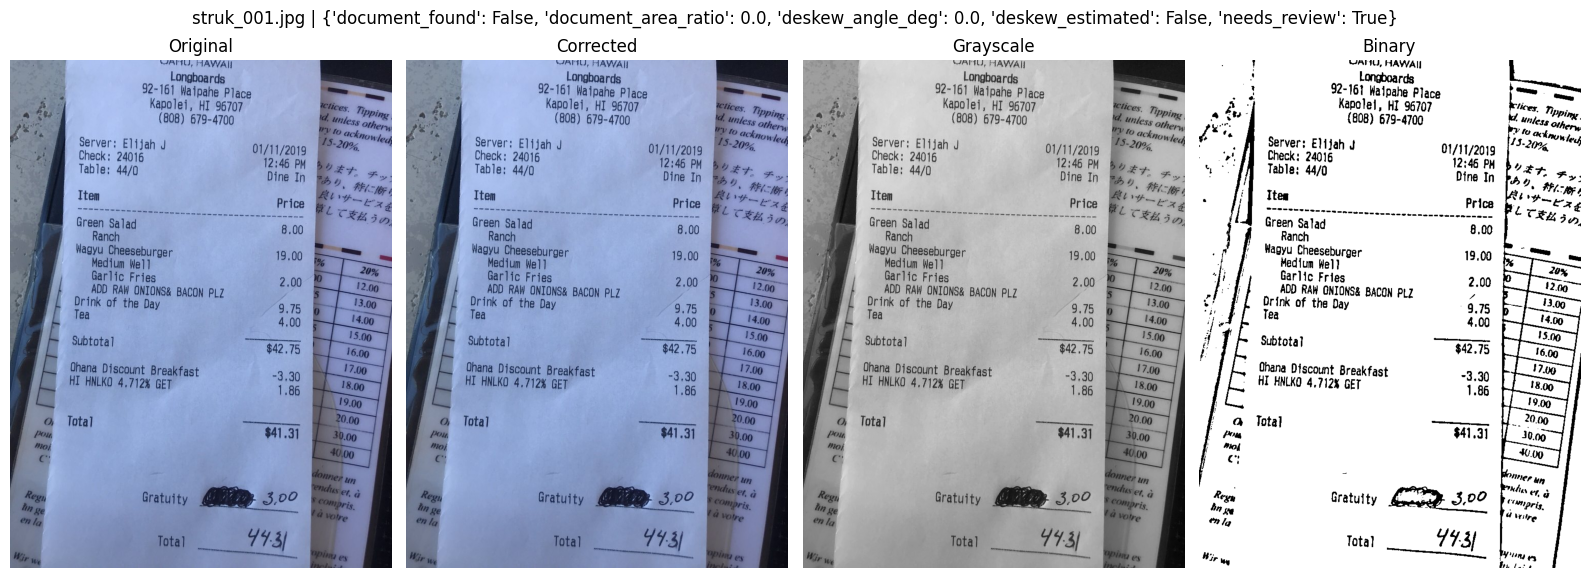

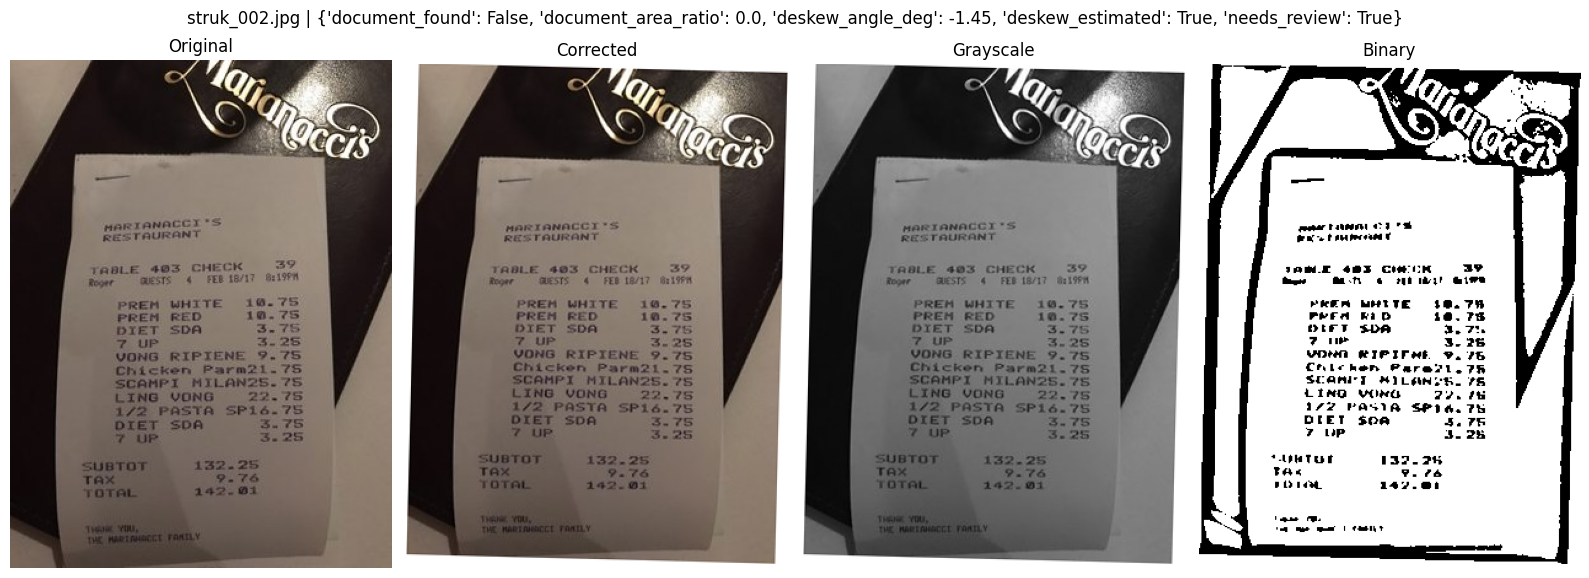

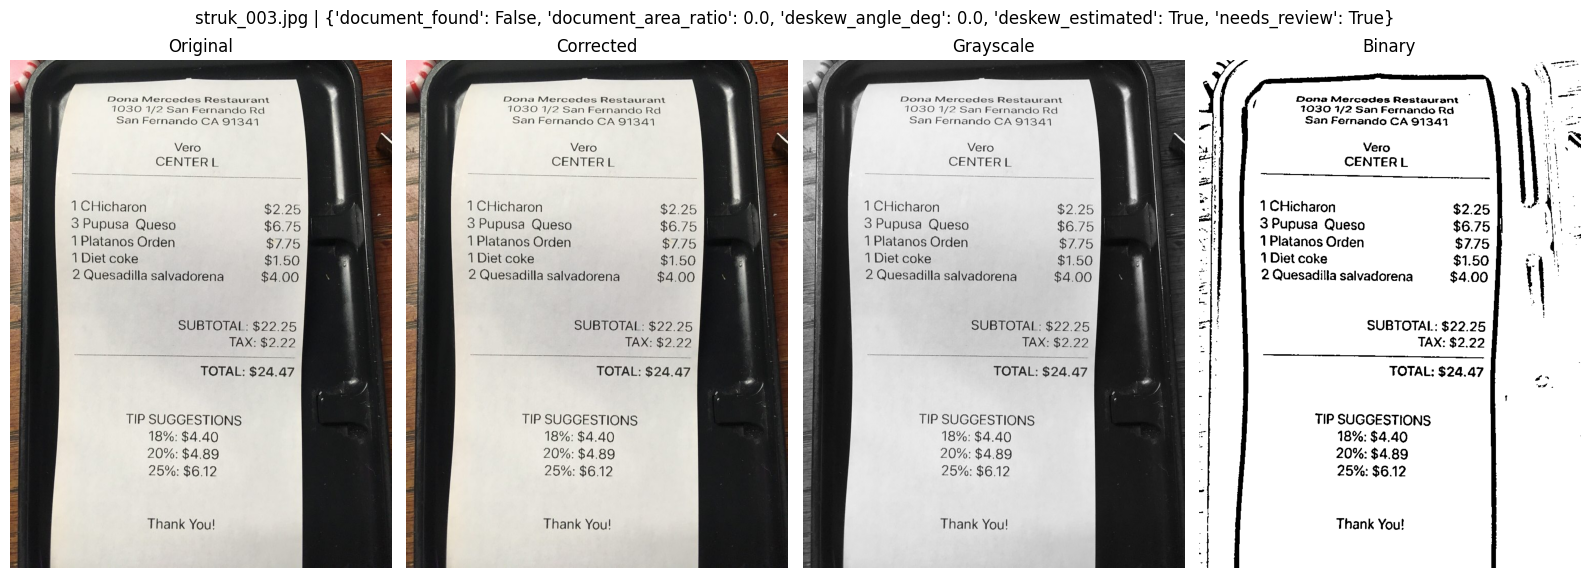

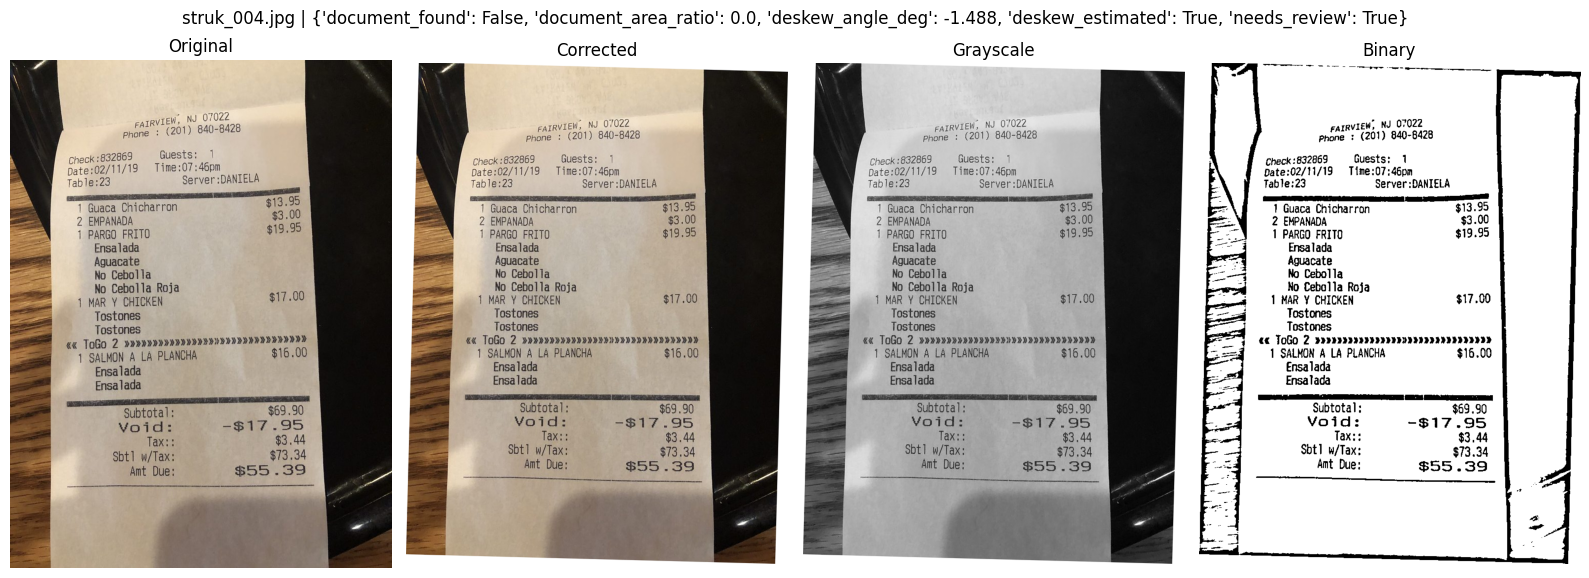

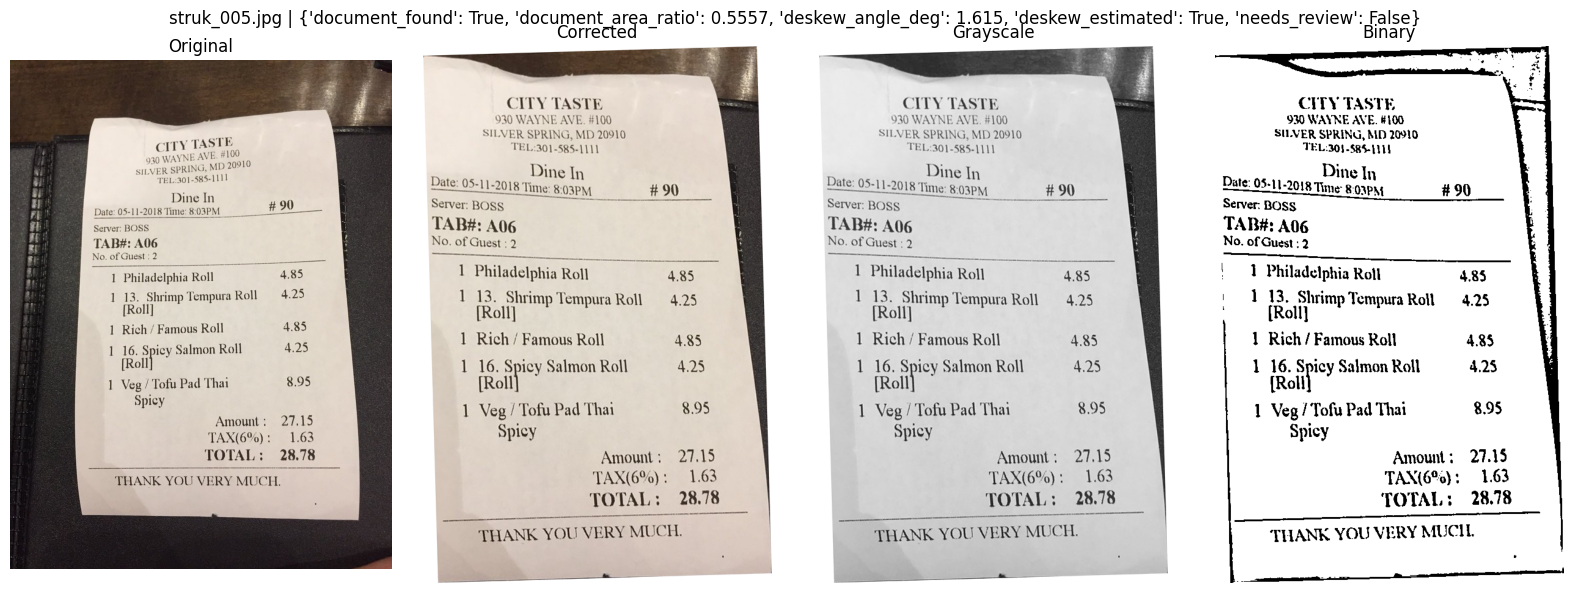

In [6]:
import matplotlib.pyplot as plt

for path in files[:5]:
    corrected, gray, binary, metadata = preprocess(path)
    original = read_image(path)

    fig, axes = plt.subplots(1, 4, figsize=(16, 6))

    panels = [
        ("Original", cv2.cvtColor(original, cv2.COLOR_BGR2RGB)),
        ("Corrected", cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB)),
        ("Grayscale", gray),
        ("Binary", binary),
    ]

    for ax, (title, image) in zip(axes, panels):
        ax.imshow(image, cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(f"{path.name} | {metadata}")
    plt.tight_layout()
    plt.show()

In [7]:
def save_image(path, image):
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise IOError(f"Gagal menyimpan: {path}")


rows = []

for path in tqdm(files, desc="Preprocessing struk"):
    relative = path.relative_to(INPUT_DIR)
    output_name = relative.with_name(relative.name + ".png")

    try:
        corrected, gray, binary, metadata = preprocess(path)

        for folder, image in [
            ("corrected", corrected),
            ("grayscale", gray),
            ("binary", binary),
        ]:
            save_image(OUTPUT_DIR / folder / output_name, image)

        rows.append({
            "file": str(relative),
            "output": str(output_name),
            "status": "ok",
            **metadata,
            "error": "",
        })

    except Exception as error:
        rows.append({
            "file": str(relative),
            "status": "error",
            "needs_review": True,
            "error": str(error),
        })

log = pd.DataFrame(rows)
log.to_csv(OUTPUT_DIR / "processing_log.csv", index=False)

display(log["status"].value_counts())
display(log[log["needs_review"].eq(True)])

Preprocessing struk:   0%|          | 0/200 [00:00<?, ?it/s]

,count
status,
ok,200


,file,output,status,document_found,document_area_ratio,deskew_angle_deg,deskew_estimated,needs_review,error
0,struk_001.jpg,struk_001.jpg.png,ok,False,0.0,0.000,False,True,
1,struk_002.jpg,struk_002.jpg.png,ok,False,0.0,-1.450,True,True,
2,struk_003.jpg,struk_003.jpg.png,ok,False,0.0,0.000,True,True,
3,struk_004.jpg,struk_004.jpg.png,ok,False,0.0,-1.488,True,True,
5,struk_006.jpg,struk_006.jpg.png,ok,False,0.0,2.253,True,True,
...,...,...,...,...,...,...,...,...,...
195,struk_196.jpg,struk_196.jpg.png,ok,False,0.0,-4.399,True,True,
196,struk_197.jpg,struk_197.jpg.png,ok,False,0.0,0.350,True,True,
197,struk_198.jpg,struk_198.jpg.png,ok,False,0.0,0.000,True,True,
198,struk_199.jpg,struk_199.jpg.png,ok,False,0.0,0.000,True,True,
